In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [6]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)

y = pd.Series(wine.target, name="Wine_Class")

print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Target:


,Wine_Class
0,0
1,0
2,0
3,0
4,0


In [7]:
print("Dataset Shape:", X.shape)

print("\nDataset Information:")
X.info()

print("\nStatistical Summary:")
display(X.describe())

print("\nTarget Distribution:")
print(y.value_counts())

Dataset Shape: (178, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline          

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



Target Distribution:
Wine_Class
1    71
0    59
2    48
Name: count, dtype: int64


Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Duplicate Rows:
0


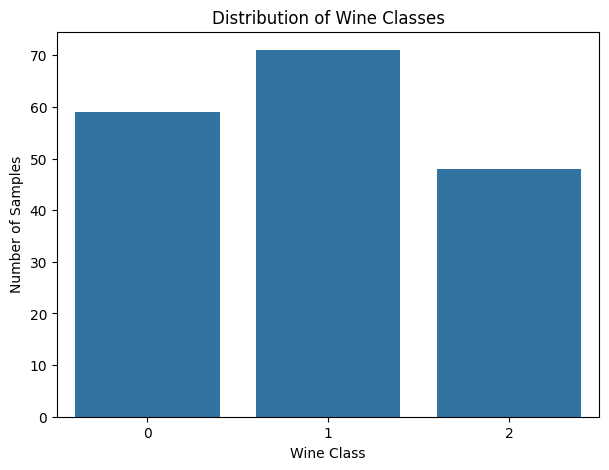

In [10]:
# Check missing values
print("Missing Values:")
print(X.isnull().sum())

#Check duplicate rows
print("\nDuplicate Rows:")
print(X.duplicated().sum())

#Visualize target distribution
plt.figure(figsize=(7,5))

sns.countplot(x=y)

plt.title("Distribution of Wine Classes")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")

plt.show()

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target", y_train.shape)
print("Testing Target", y_test.shape)

Training Features: (142, 13)
Testing Features: (36, 13)
Training Target (142,)
Testing Target (36,)


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Original Training Data:")
display(X_train.head())

print("\nScaled Training Data:")
print(X_train_scaled[:5])

Original Training Data:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
36,13.28,1.64,2.84,15.5,110.0,2.60,2.68,0.34,1.36,4.60,1.09,2.78,880.0
30,13.73,1.50,2.70,22.5,101.0,3.00,3.25,0.29,2.38,5.70,1.19,2.71,1285.0
26,13.39,1.77,2.62,16.1,93.0,2.85,2.94,0.34,1.45,4.80,0.92,3.22,1195.0
12,13.75,1.73,2.41,16.0,89.0,2.60,2.76,0.29,1.81,5.60,1.15,2.90,1320.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0



Scaled Training Data:
[[ 0.38580089 -0.63787118  1.77666817 -1.22453161  0.69643032  0.52686525
   0.73229212 -0.1695489  -0.41578344 -0.16746725  0.62437819  0.2529082
   0.46772474]
 [ 0.94851892 -0.76544542  1.25317383  0.85328406  0.09178497  1.17279546
   1.33318146 -0.59045701  1.34974202  0.30530313  1.06715537  0.15104809
   1.81576773]
 [ 0.52335419 -0.51940939  0.9540342  -1.04643312 -0.44567755  0.93057163
   1.006382   -0.1695489  -0.26000178 -0.081509   -0.12834302  0.89317174
   1.51620262]
 [ 0.97352861 -0.55585917  0.16879269 -1.0761162  -0.71440882  0.52686525
   0.81662747 -0.59045701  0.36312485  0.262324    0.8900445   0.42752553
   1.93226527]
 [ 0.43582027  0.82012009  0.05661533  0.55645325 -0.51286037 -0.55506784
  -1.29175618  0.75644894 -0.60618325  1.47433535 -1.76661859 -1.43505932
  -0.29783054]]


In [14]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model training completed!")

Model training completed!


In [15]:
y_pred = model.predict(X_test_scaled)

print("Actual Wine Classes:")
print(y_test.values)

print("\nPredicted Wine Classes:")
print(y_pred)

Actual Wine Classes:
[0 2 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]

Predicted Wine Classes:
[0 1 0 1 1 0 0 1 1 2 1 2 0 2 0 1 1 0 1 0 1 1 0 0 1 1 0 2 1 2 0 2 1 2 2 2]


In [16]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9722222222222222
Accuracy Percentage: 97.22222222222221 %


Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]


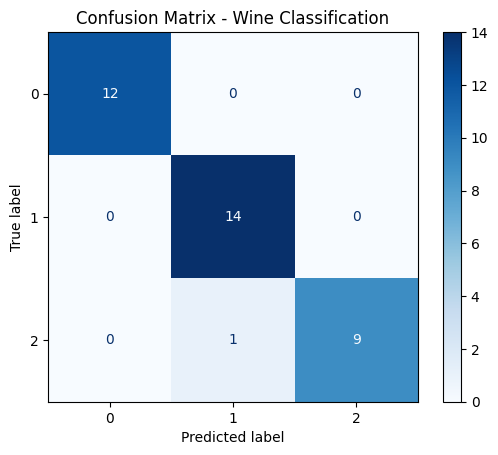

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Wine Classification")
plt.show()

In [18]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



In [19]:
import joblib

joblib.dump(model, "wine_classification_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [20]:
joblib.dump(model, "wine_classification_model.pkl")
joblib.dump(scaler, "wine_scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [21]:
import joblib

loaded_model = joblib.load("wine_classification_model.pkl")
loaded_scaler = joblib.load("wine_scaler.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [22]:
import pandas as pd

new_wine = pd.DataFrame([[
    13.0, 2.0, 2.4, 18.0, 100.0,
    2.5, 2.5, 0.3, 1.8, 5.0,
    1.0, 3.0, 1000.0
]], columns=X.columns)

new_wine_scaled = loaded_scaler.transform(new_wine)

prediction = loaded_model.predict(new_wine_scaled)

print("Predicted Wine Class:", prediction[0])

Predicted Wine Class: 0


In [23]:
from sklearn.datasets import load_wine

wine_data = load_wine()

print("Wine Class Names:")
print(wine_data.target_names)

Wine Class Names:
['class_0' 'class_1' 'class_2']


In [24]:
predicted_class = wine_data.target_names[prediction[0]]

print("Predicted Wine Category:", predicted_class)

Predicted Wine Category: class_0


In [27]:
import pandas as pd
import numpy as np
from IPython.display import display

# Calculate average absolute coefficient for each feature
importance = np.mean(np.abs(model.coef_), axis=0)

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the result
display(feature_importance)

,Feature,Importance
9,color_intensity,0.730677
12,proline,0.673270
6,flavanoids,0.602310
0,alcohol,0.574358
3,alcalinity_of_ash,0.556709
2,ash,0.538171
10,hue,0.470410
11,od280/od315_of_diluted_wines,0.466792
1,malic_acid,0.341441
8,proanthocyanins,0.330515


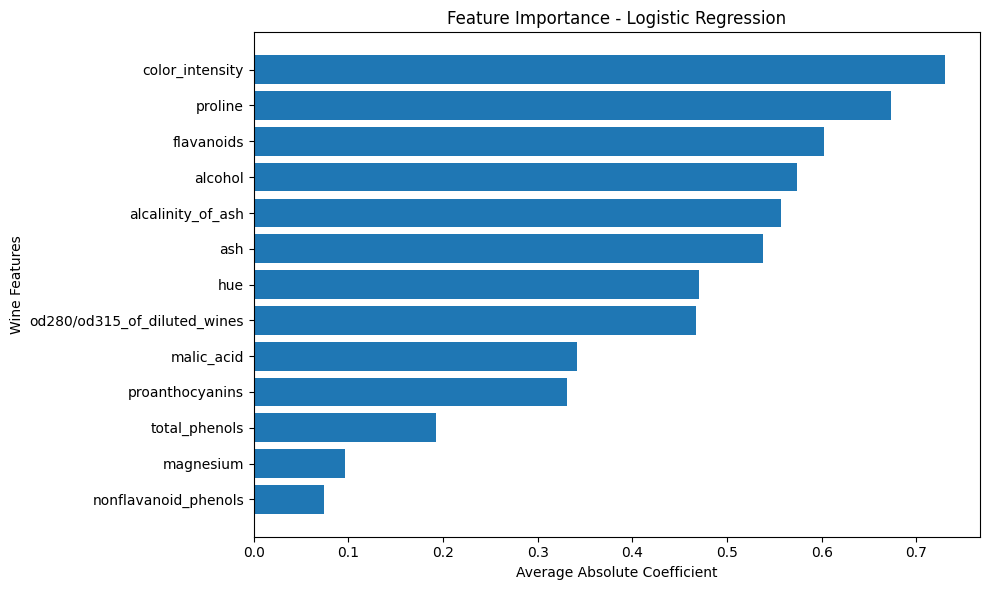

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Average Absolute Coefficient")
plt.ylabel("Wine Features")
plt.title("Feature Importance - Logistic Regression")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [30]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np

pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", cv_scores)
print("Average CV Accuracy:", np.mean(cv_scores) * 100, "%")
print("Standard Deviation:", np.std(cv_scores))

Cross-validation scores: [0.93103448 1.         1.         1.         0.96428571]
Average CV Accuracy: 97.90640394088669 %
Standard Deviation: 0.027713464392187602


In [31]:
# Train the pipeline on the complete training dataset
pipeline.fit(X_train, y_train)

# Predict the test dataset
y_test_pred = pipeline.predict(X_test)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Final Test Accuracy:", test_accuracy * 100, "%")

Final Test Accuracy: 97.22222222222221 %


In [32]:
import joblib

# Save the complete pipeline
joblib.dump(pipeline, "wine_classification_pipeline.pkl")

print("Final pipeline saved successfully!")

Final pipeline saved successfully!
